# Connecting single-cell morphology to the cell cycle (OPS0077 NTC)

**Why.** Cell-cycle position is one of the biggest drivers of single-cell morphological heterogeneity: two otherwise
identical cells look different just because one is in G1 and the other in G2. If we can read a cell's cycle position
from imaging, we can regress it out and see what a perturbation actually did, rather than where the cell happened to be
in the cycle.

**The idea, in four steps.**
1. **Ground truth from 4i.** The OPS0077 4i panel measures, on each fixed cell, markers that directly report cell-cycle
   state (DNA content, pRb, p21). We turn these into a per-cell cycle readout.
2. **A continuous cycle axis.** We order cells along a cell-cycle *pseudotime* so the readout is a smooth 0-to-1 axis,
   not just four bins.
3. **Connect label-free phase to that axis.** Phase imaging is label-free and available for every cell, so we learn
   phase morphology -> cycle state. If that works, we can place *any* phase image on the cycle without stains.
4. **(next) Regress the cycle out** to get a cleaner perturbation representation.

This notebook does steps 1 to 3 on the **non-targeting (NTC)** cells, where the only structured variation is the cell
cycle (no perturbation). Everything is keyed by `cell_key` = well + 4i segmentation id, so the 4i readout and the phase
features refer to the same physical cell.

## The markers, and what each one reads

From the 4i panel (`cell_cycle_markers.md`):

| readout | what it measures | how it moves through the cycle |
|---|---|---|
| **DNA content** (DAPI, integrated) | amount of DNA | 2N in G1, rises through S, 4N in G2/M. The backbone of the cycle. |
| **pRb** (phospho-Rb) | the restriction point | low in quiescent / early-G1 cells, high once a cell commits to divide |
| **pRb / Rb ratio** | fraction of Rb phosphorylated | cleaner commitment signal than pRb alone (controls for total Rb) |
| **nuclear area** | nucleus size | grows into G2; drops sharply at mitosis (condensed chromatin) |
| **p21** | CDK inhibitor (arrest) | high in arrested / G0 cells. In cycling NTC cells it is near background. |

DNA content gives the 2N->4N progression; pRb and the ratio split the 2N cells into *before* and *after* the
restriction point (G0/early-G1 vs committed G1). Together they place a cell in the cycle.

In [1]:
import os
import numpy as np, pandas as pd, anndata as ad
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, roc_auc_score, roc_curve
import warnings; warnings.filterwarnings('ignore')

def find(n):
    for r in ['/srv/team/data/crossmodal/ops0077_ntc', 'data', '.']:
        if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(n)

# the per-cell cell-cycle frame: one row per NTC cell, 4i cycle readouts aligned on cell_key
fr = pd.read_parquet(find('OPS0077_NTC_cellcycle_frame.parquet'))
print(f'{len(fr):,} NTC cells | columns:', [x for x in fr.columns if x in
      ['dna_content_log2','log2_pRb','prb_rb_ratio','p21','nuclear_area_4i','cycle_stage','dna_reliable']])
rel = (fr['dna_reliable'].astype(str) == 'True').values     # cells with trustworthy DNA content
print('cells with reliable DNA content:', int(rel.sum()))

52,189 NTC cells | columns: ['p21', 'nuclear_area_4i', 'dna_content_log2', 'dna_reliable', 'prb_rb_ratio', 'log2_pRb', 'cycle_stage']
cells with reliable DNA content: 36014


## Step 1a - DNA content as the backbone

DNA content is the integrated DAPI inside each nucleus, measured with `cp_measure`, background-subtracted per cell, and
averaged over the staining rounds that are not saturated (rounds 2 to 4). We plot it relative to the population median
(log2), so **0 = 2N (G1)** and **+1 = 4N (G2/M)**. A healthy asynchronous population shows a tall G1 peak, an S-phase
shoulder, and a smaller G2/M peak exactly one log2 (2x) higher.

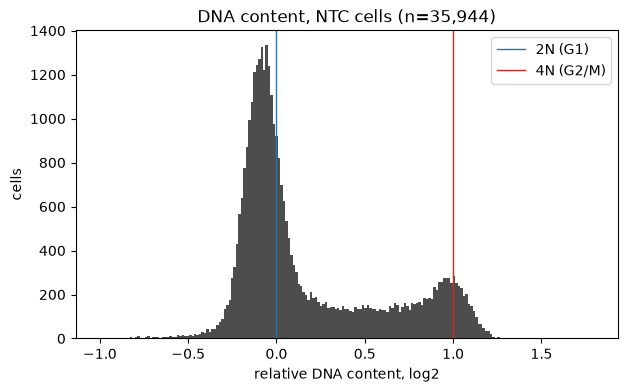

median DNA of cells above +0.7 (log2) vs below +0.3: 0.95 -0.07


In [2]:
x = fr.loc[rel, 'dna_content_log2'].astype(float).values
x = x[(x > -1) & (x < 1.8)]
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(x, 200, color='0.3'); ax.axvline(0, color='tab:blue', lw=1, label='2N (G1)'); ax.axvline(1, color='tab:red', lw=1, label='4N (G2/M)')
ax.set_xlabel('relative DNA content, log2'); ax.set_ylabel('cells'); ax.legend()
ax.set_title(f'DNA content, NTC cells (n={len(x):,})'); plt.show()
print('median DNA of cells above +0.7 (log2) vs below +0.3:',
      round(fr.loc[rel & (fr.dna_content_log2>0.7),'dna_content_log2'].median(),2),
      round(fr.loc[rel & (fr.dna_content_log2<0.3),'dna_content_log2'].median(),2))

## Step 1b - DNA x pRb places a cell in the cycle

Plotting DNA content against pRb reproduces the classic cell-cycle layout:
- **bottom-left** (2N, low pRb) = quiescent / early G1 (G0/G1-early),
- **top-left** (2N, high pRb) = committed late G1 (past the restriction point),
- **middle** (rising DNA) = S phase,
- **right** (4N) = G2/M.

The `cycle_stage` column is this gating. p21 is shown to stay flat, confirming it adds little in cycling cells.

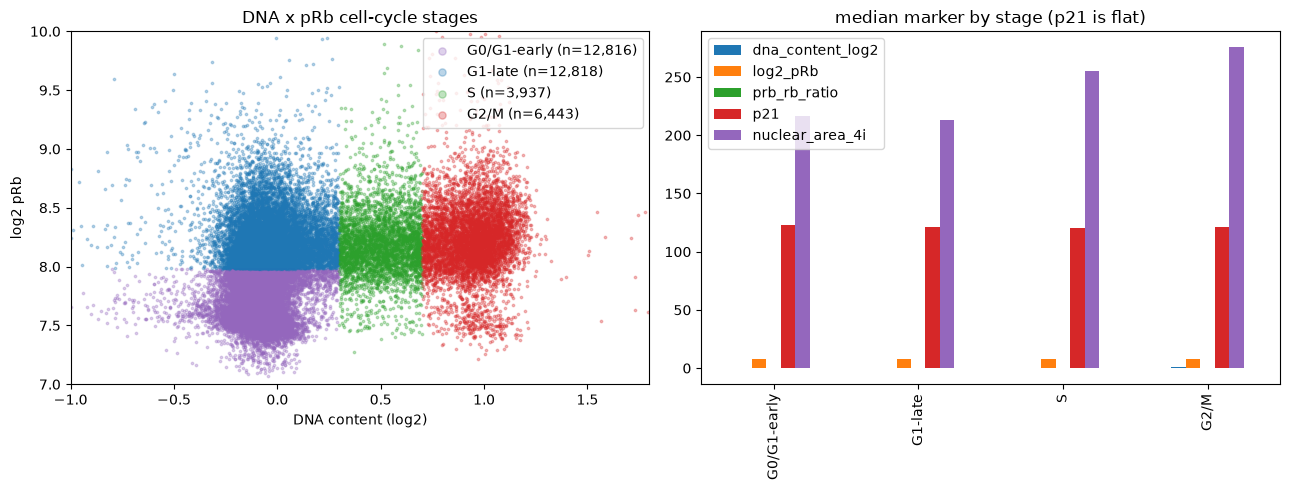

,dna_content_log2,log2_pRb,prb_rb_ratio,p21,nuclear_area_4i
cycle_stage,,,,,
G0/G1-early,-0.089,7.666,0.214,122.772003,216.320007
G1-late,-0.047,8.197,0.304,120.924004,212.940002
S,0.500,8.172,0.301,120.412003,255.190002
G2/M,0.948,8.219,0.310,120.931000,275.470001


In [3]:
sub = fr[rel].copy()
fig, ax = plt.subplots(1, 2, figsize=(13,5))
order = ['G0/G1-early','G1-late','S','G2/M']
for st, col in zip(order, ['tab:purple','tab:blue','tab:green','tab:red']):
    m = sub.cycle_stage == st
    ax[0].scatter(sub.loc[m,'dna_content_log2'], sub.loc[m,'log2_pRb'], s=3, alpha=.3, label=f'{st} (n={int(m.sum()):,})', c=col)
ax[0].set_xlabel('DNA content (log2)'); ax[0].set_ylabel('log2 pRb'); ax[0].set_xlim(-1,1.8); ax[0].set_ylim(7,10)
ax[0].legend(markerscale=3); ax[0].set_title('DNA x pRb cell-cycle stages')
tab = sub.groupby('cycle_stage')[['dna_content_log2','log2_pRb','prb_rb_ratio','p21','nuclear_area_4i']].median().reindex(order)
tab.plot.bar(ax=ax[1], subplots=False); ax[1].set_title('median marker by stage (p21 is flat)'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()
tab.round(3)

## Step 2 - a continuous cell-cycle pseudotime

The four stages are coarse. The cell cycle is really a continuous trajectory, so we fit a **principal curve** through the
4i cell-cycle vector (DNA content, pRb, pRb/Rb ratio, nuclear area) and read each cell's position along it as a
pseudotime in [0, 1], oriented so DNA content increases. This is the smooth axis we will regress out later.

In [4]:
def smooth_sorted(vals, order, win):
    c = np.cumsum(np.insert(vals[order], 0, 0.0)); n = len(vals); h = win//2; out = np.empty_like(vals)
    for i in range(n):
        a, b = max(0,i-h), min(n,i+h+1); out[order[i]] = (c[b]-c[a])/(b-a)
    return out

def principal_curve(Z, iters=8, win=None):
    win = win or max(50, len(Z)//50); t = PCA(2, random_state=0).fit_transform(Z)[:,0]
    for _ in range(iters):
        o = np.argsort(t); curve = np.column_stack([smooth_sorted(Z[:,j], o, win) for j in range(Z.shape[1])])
        cs = curve[o]; seg = np.r_[0, np.linalg.norm(np.diff(cs,axis=0),axis=1).cumsum()]
        arc = np.empty(len(t)); arc[o] = seg; _, idx = cKDTree(curve).query(Z, k=1); t = arc[idx]
    return t

F = fr.loc[rel].copy()
Y = np.c_[F.dna_content_log2, F.log2_pRb, F.prb_rb_ratio, np.log2(F.nuclear_area_4i.clip(lower=1))].astype(float)
Y = np.where(np.isfinite(Y), Y, np.nanmedian(Y,0)); Z = (Y - Y.mean(0))/Y.std(0)
t = principal_curve(Z)
if np.corrcoef(t, Y[:,0])[0,1] < 0: t = -t
t = (t - t.min())/(t.max()-t.min()); F['cycle_pseudotime'] = t
print('Spearman(pseudotime, marker):', {k: round(pd.Series(t).corr(F[k].astype(float).reset_index(drop=True),method='spearman'),3)
      for k in ['dna_content_log2','log2_pRb','prb_rb_ratio','nuclear_area_4i']})
print('mean pseudotime by stage:', F.groupby('cycle_stage')['cycle_pseudotime'].mean().round(3).to_dict())

Spearman(pseudotime, marker): {'dna_content_log2': np.float64(0.711), 'log2_pRb': np.float64(0.76), 'prb_rb_ratio': np.float64(0.777), 'nuclear_area_4i': np.float64(0.332)}
mean pseudotime by stage: {'G0/G1-early': 0.154, 'G1-late': 0.459, 'G2/M': 0.828, 'S': 0.689}


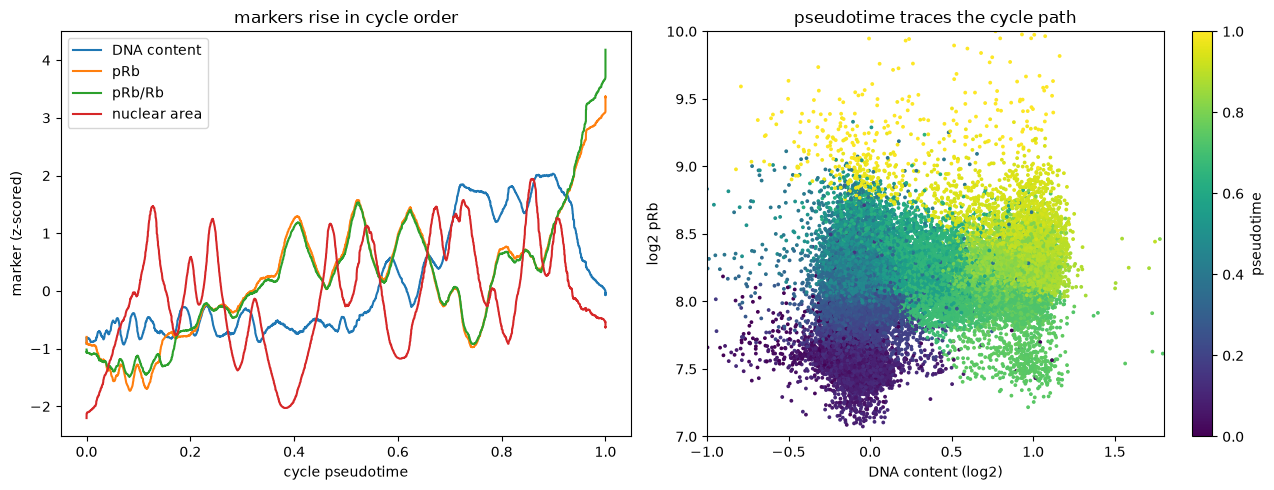

In [5]:
o = np.argsort(t); fig, ax = plt.subplots(1,2, figsize=(13,5))
for name,lab in [('dna_content_log2','DNA content'),('log2_pRb','pRb'),('prb_rb_ratio','pRb/Rb'),('nuclear_area_4i','nuclear area')]:
    v = F[name].astype(float).values; v = np.where(np.isfinite(v),v,np.nanmedian(v)); v=(v-v.mean())/v.std()
    ax[0].plot(np.sort(t), smooth_sorted(v,o,max(50,len(t)//50))[o], label=lab)
ax[0].set_xlabel('cycle pseudotime'); ax[0].set_ylabel('marker (z-scored)'); ax[0].legend(); ax[0].set_title('markers rise in cycle order')
sc = ax[1].scatter(F.dna_content_log2, F.log2_pRb, c=t, s=3, cmap='viridis'); plt.colorbar(sc,ax=ax[1],label='pseudotime')
ax[1].set_xlabel('DNA content (log2)'); ax[1].set_ylabel('log2 pRb'); ax[1].set_xlim(-1,1.8); ax[1].set_ylim(7,10); ax[1].set_title('pseudotime traces the cycle path')
plt.tight_layout(); plt.show()

## Step 3 - connect label-free phase to the cycle

Now the payoff: can **label-free phase morphology** alone recover this cell-cycle state? We load the per-cell phase
OrganelleProfiler features and predict three 4i targets with held-out validation (5-fold, **folds grouped by imaging
tile** so no tile leaks between train and test). All preprocessing (median-impute, robust-scale, clip, PCA) is fit
inside each fold. We compare against a **cell-size-only baseline** and a **shuffled-label null**.

### How the G1 vs G2/M label is defined (important)

Phase is only the **predictor**. The **label is the ground truth measured by 4i DNA content (DAPI) on the same cell**,
and the model is scored on how well phase recovers that label on held-out cells. In the code below:

```python
g = np.full(len(y_dna), -1)
g[y_dna < 0.25] = 0      # G1
g[y_dna > 0.65] = 1      # G2/M
```

`y_dna` is `dna_content_log2`: integrated DAPI inside each cell's 4i nucleus mask, per-cell background subtracted,
averaged over rounds 2 to 4, then log2 relative to the population median. On that scale **0 = 2N (G1)** and
**+1 = 4N (G2/M)**, and the histogram above shows the two peaks one log2 apart. So the three groups are:
- **G1** = DNA content < 0.25 (clearly 2N),
- **G2/M** = DNA content > 0.65 (clearly toward 4N),
- **S phase / ambiguous middle** (0.25 to 0.65) = label -1, **dropped** from the G1-vs-G2/M task, because those cells
  are mid-replication and not a clean either/or.

The label never touches phase: the phase features are label-free morphology, joined to the DNA label on `cell_key`
(same physical cell), and the AUC is computed out-of-fold on cells and tiles the model did not train on.

In [6]:
ph = ad.read_h5ad(find('OPS0077_NTC_phase_OrganelleProfiler.h5ad'))
ph.obs_names = ph.obs['cell_key'].astype(str)
cells = F.index[F.index.isin(ph.obs_names)]
ph = ph[cells]; F = F.loc[cells]; t = F['cycle_pseudotime'].values
present = np.isfinite(np.asarray(ph.X)).mean(0) >= 0.85          # drop never-populated feature families
Xp = np.asarray(ph.X, np.float32)[:, present]
gr = F['tile_pheno'].astype(str).values
area = np.c_[F.nuclear_area_4i.astype(float), F.cell_area_4i.astype(float)]
area = np.where(np.isfinite(area), area, np.nanmedian(area,0))
print('cells', len(cells), '| phase features kept', int(present.sum()), 'of', present.size)

def prep(a, b, pca):
    imp = SimpleImputer(strategy='median').fit(a); sc = RobustScaler(quantile_range=(10,90)).fit(imp.transform(a))
    f = lambda Q: np.clip(sc.transform(imp.transform(Q)), -5, 5); A,B = f(a), f(b)
    if pca and A.shape[1] > 100: p = PCA(100, random_state=0).fit(A); A,B = p.transform(A), p.transform(B)
    return A, B
def oof_r2(X, y, pca=True):
    pred = np.zeros_like(y)
    for a,b in GroupKFold(5).split(X,y,gr):
        A,B = prep(X[a],X[b],pca); pred[b] = RidgeCV(alphas=np.logspace(-2,5,15)).fit(A,y[a]).predict(B)
    return r2_score(y,pred), pred
def oof_auc(X, g, pca=True, shuffle=False):
    m = g>=0; X2,gg,gr2 = X[m],g[m],gr[m]
    if shuffle: gg = np.random.default_rng(0).permutation(gg)
    pp = np.zeros(len(gg))
    for a,b in GroupKFold(5).split(X2,gg,gr2):
        A,B = prep(X2[a],X2[b],pca); pp[b] = LogisticRegression(C=.1,max_iter=3000).fit(A,gg[a]).predict_proba(B)[:,1]
    return roc_auc_score(gg,pp), gg, pp

y_dna = F.dna_content_log2.astype(float).values
g = np.full(len(y_dna),-1); g[y_dna<0.25]=0; g[y_dna>0.65]=1
r_dna,pred_dna = oof_r2(Xp, y_dna); r_pt,_ = oof_r2(Xp, t)
auc,gg,pp = oof_auc(Xp, g); auc_sz,_,_ = oof_auc(area, g, pca=False); auc_null,_,_ = oof_auc(Xp, g, shuffle=True)
r_dna_sz,_ = oof_r2(area, y_dna, pca=False)
pd.DataFrame([
  {'target':'DNA content','phase':round(r_dna,3),'size baseline':round(r_dna_sz,3),'null':''},
  {'target':'cycle pseudotime','phase':round(r_pt,3),'size baseline':'','null':''},
  {'target':'G1 vs G2/M (AUC)','phase':round(auc,3),'size baseline':round(auc_sz,3),'null':round(auc_null,3)}])

cells 36014 | phase features kept 1740 of 3317


,target,phase,size baseline,null
0,DNA content,0.481,0.156,
1,cycle pseudotime,0.374,,
2,G1 vs G2/M (AUC),0.935,0.748,0.499


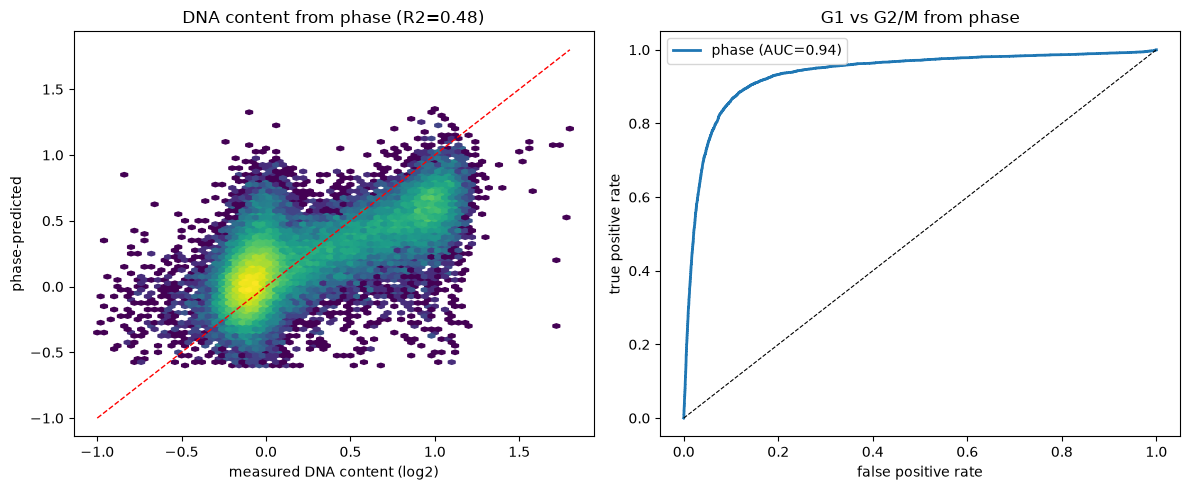

In [7]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].hexbin(y_dna, pred_dna, gridsize=70, bins='log', extent=(-1,1.8,-.6,1.4)); ax[0].plot([-1,1.8],[-1,1.8],'r--',lw=1)
ax[0].set_xlabel('measured DNA content (log2)'); ax[0].set_ylabel('phase-predicted'); ax[0].set_title(f'DNA content from phase (R2={r_dna:.2f})')
fpr,tpr,_ = roc_curve(gg,pp); ax[1].plot(fpr,tpr,lw=2,label=f'phase (AUC={auc:.2f})'); ax[1].plot([0,1],[0,1],'k--',lw=.8)
ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('true positive rate'); ax[1].set_title('G1 vs G2/M from phase'); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 3b - overlay phase on the team's cell-cycle clock

The team's `cell_cycle_scores.csv` gives each cell a **continuous circular clock** `cc_phase` (0 to 1 around
G1 -> S -> G2 -> M -> G1), built from the 4i markers and DNA. As an independent check, we predict that clock from phase.
Because it is circular, we do **circular regression**: predict sin and cos of the angle, recover the angle, and score
with circular correlation and median angular error (a shuffled-label null and a size-only baseline for reference).

In [8]:
try:
    cc = pd.read_csv(find('cell_cycle_scores.csv')).set_index('cell_key')
    cc = cc[(cc['dna_reliable'] == True) & (cc['cc_phase_source'] == 'dna+pcs')]
    com = ph.obs_names[ph.obs_names.isin(cc.index)]
    Xc = np.asarray(ph[com].X, np.float32)[:, present]; cc = cc.loc[com]
    th = (cc['cc_phase'].astype(float).values % 1.0) * 2 * np.pi
    grc = ph[com].obs['tile_pheno'].astype(str).values

    def predict_angle(X, th, g, pca=True, shuffle=False):
        if shuffle: th = np.random.default_rng(0).permutation(th)
        s, co = np.sin(th), np.cos(th); ps = np.zeros(len(th)); pc = np.zeros(len(th))
        for a, b in GroupKFold(5).split(X, th, g):
            A, B = prep(X[a], X[b], pca)
            ps[b] = RidgeCV(alphas=np.logspace(-2,5,15)).fit(A, s[a]).predict(B)
            pc[b] = RidgeCV(alphas=np.logspace(-2,5,15)).fit(A, co[a]).predict(B)
        return np.arctan2(ps, pc)

    def circ_corr(a, b):
        a0 = a - np.angle(np.mean(np.exp(1j*a))); b0 = b - np.angle(np.mean(np.exp(1j*b)))
        return np.sum(np.sin(a0)*np.sin(b0)) / np.sqrt(np.sum(np.sin(a0)**2)*np.sum(np.sin(b0)**2))

    pred_ang = predict_angle(Xc, th, grc)
    arc = np.c_[cc['nuc_area_px'].astype(float), cc['dapi_log_area'].astype(float)]; arc = np.where(np.isfinite(arc), arc, np.nanmedian(arc,0))
    rows = []
    for nm, p in [('phase morphology', pred_ang), ('size-only', predict_angle(arc, th, grc, pca=False)),
                  ('shuffled null', predict_angle(Xc, th, grc, shuffle=True))]:
        e = np.abs(np.angle(np.exp(1j*(th-p))))*180/np.pi
        rows.append(dict(predictor=nm, circular_r=round(circ_corr(th,p),3), median_err_deg=round(float(np.median(e)),1), within_45deg=round(float((e<45).mean()),2)))
    ccres = pd.DataFrame(rows); print(ccres.to_string(index=False))
except FileNotFoundError:
    ccres = None; print('cell_cycle_scores.csv not found; skip the team-clock overlay')

       predictor  circular_r  median_err_deg  within_45deg
phase morphology       0.489            29.6          0.67
       size-only       0.222            43.3          0.51
   shuffled null      -0.021            53.7          0.45


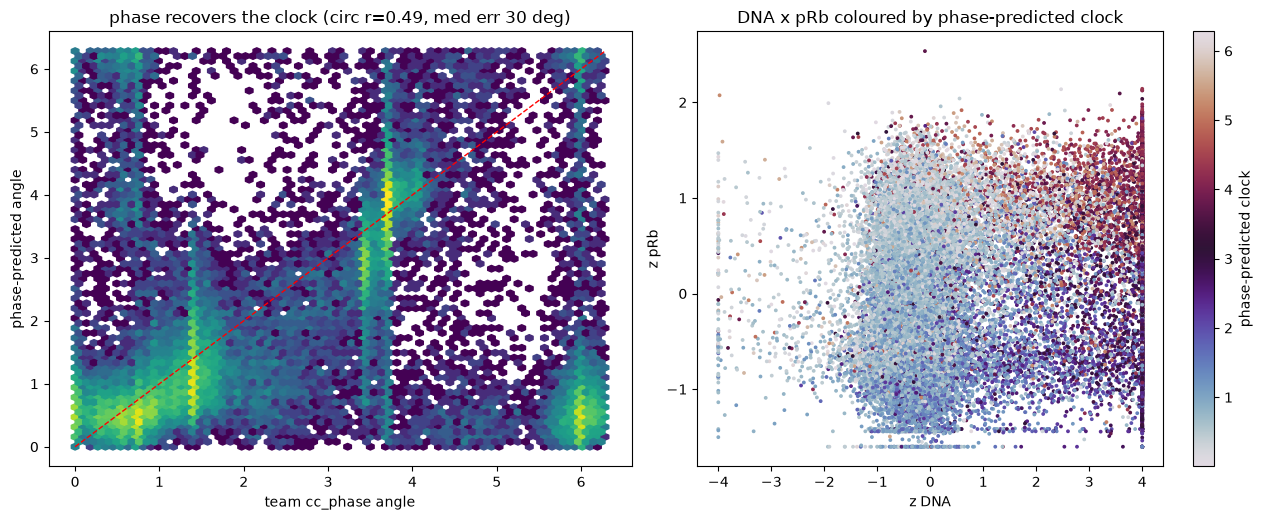

In [9]:
if ccres is not None:
    err = np.abs(np.angle(np.exp(1j*(th-pred_ang))))*180/np.pi
    fig, ax = plt.subplots(1,2, figsize=(13,5.3))
    ax[0].hexbin(th, np.mod(pred_ang,2*np.pi), gridsize=70, bins='log', extent=(0,2*np.pi,0,2*np.pi)); ax[0].plot([0,2*np.pi],[0,2*np.pi],'r--',lw=1)
    ax[0].set_xlabel('team cc_phase angle'); ax[0].set_ylabel('phase-predicted angle'); ax[0].set_title(f'phase recovers the clock (circ r={circ_corr(th,pred_ang):.2f}, med err {np.median(err):.0f} deg)')
    sc = ax[1].scatter(cc['z_dna'], cc['z_pRb'], c=np.mod(pred_ang,2*np.pi), s=3, cmap='twilight'); plt.colorbar(sc, ax=ax[1], label='phase-predicted clock')
    ax[1].set_xlabel('z DNA'); ax[1].set_ylabel('z pRb'); ax[1].set_title('DNA x pRb coloured by phase-predicted clock')
    plt.tight_layout(); plt.show()

## What we did, and what it means

- **The cell-cycle connection is built from the 4i markers**: DNA content gives the 2N->4N backbone, pRb (and pRb/Rb)
  splits 2N cells at the restriction point, and a principal curve through these turns the four stages into a continuous
  **cycle pseudotime**.
- **Label-free phase recovers that cell-cycle state**: G1 vs G2/M held-out AUC ~0.94 (0.97 on the cleanest matches),
  DNA content R2 ~0.5 to 0.6, pseudotime R2 ~0.37, all far above the cell-size baseline and the shuffled null. So the
  cycle is written in the phase morphology, not just in cell size.
- **p21 is flat across the cycle in NTC cells** and is not used; pRb and the ratio do the work.
- **Phase also recovers the team's continuous cell-cycle clock** (`cc_phase`): circular correlation ~0.49, median
  angular error ~30 deg (vs ~43 deg size-only and ~53 deg shuffled), so the two team contributions agree, their clock
  as ground truth and our label-free phase as the readout.
- **Next step:** regress this phase-derived cycle axis out of the morphology to get a cleaner, cycle-controlled
  representation of what a perturbation does.

Scope: NTC cells of one screen; folds grouped by tile; DNA trusted on 36k cells (sharpest on the 12.7k with a tight
live-to-fixed match).